# Exploratory Data Analysis (EDA) on Retail Sales Data

**Objective:** Explore retail transactions to understand sales trends, customer demographics, and product/category performance, then provide actionable business recommendations.

**Tools:** Python, pandas, Matplotlib, Seaborn, Jupyter Notebook.

> **Dataset note:** This notebook is designed for the common Kaggle Retail Sales Dataset with columns such as `Date`, `Gender`, `Age`, `Product Category`, `Quantity`, `Price per Unit`, and `Total Amount`. If your dataset uses different column names, update the column mapping in the next section. Some versions contain categories but not individual product names; in that case, the notebook analyzes categories rather than claiming to identify individual products.

## 1. Import libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## 2. Load the dataset

Place your CSV file at `data/retail_sales.csv` in the repository. If you're running this in Google Colab, you can upload the file when prompted.

In [3]:
csv_path = Path("../data/retail_sales.csv")

if not csv_path.exists():
    try:
        from google.colab import files
        uploaded = files.upload()
        csv_path = Path(next(iter(uploaded)))
    except ImportError:
        raise FileNotFoundError(
            "Could not find ../data/retail_sales.csv. Place your CSV in the data folder "
            "or run this notebook in Google Colab and upload it."
        )

df = pd.read_csv(csv_path)
print("Dataset loaded successfully.")
df.head()

Saving retail_sales_dataset.csv to retail_sales_dataset.csv
Dataset loaded successfully.


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


## 3. Standardize column names and inspect the data

In [4]:
# Normalize common naming differences while keeping readable column names.
df.columns = (
    df.columns.astype(str)
      .str.strip()
      .str.replace("_", " ", regex=False)
      .str.replace(r"\s+", " ", regex=True)
)

# Map common alternative column names to the names used in this notebook.
rename_map = {
    "Transaction ID": "Transaction ID",
    "Transaction.ID": "Transaction ID",
    "Customer ID": "Customer ID",
    "Customer.ID": "Customer ID",
    "Product Category": "Product Category",
    "Product.Category": "Product Category",
    "Price per Unit": "Price per Unit",
    "Price Per Unit": "Price per Unit",
    "Total Amount": "Total Amount",
    "Total.Amount": "Total Amount",
    "Order Date": "Date",
    "date": "Date",
}
df = df.rename(columns={c: rename_map[c] for c in df.columns if c in rename_map})

print("Rows and columns:", df.shape)
print("\nColumn names:", df.columns.tolist())
display(df.head())
display(df.info())
display(df.isnull().sum().to_frame("Missing values"))
print("Duplicate rows:", df.duplicated().sum())

Rows and columns: (1000, 9)

Column names: ['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB


None

,Missing values
Transaction ID,0
Date,0
Customer ID,0
Gender,0
Age,0
Product Category,0
Quantity,0
Price per Unit,0
Total Amount,0


Duplicate rows: 0


## 4. Clean and prepare the data

In [5]:
# Convert date column if present.
if "Date" in df.columns:
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Convert expected numeric columns where present.
numeric_candidates = ["Age", "Quantity", "Price per Unit", "Total Amount"]
for col in numeric_candidates:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove exact duplicate rows.
before = len(df)
df = df.drop_duplicates().copy()
print(f"Removed {before - len(df)} duplicate rows.")

# Report missing values before deciding how to handle them.
print("Missing values after type conversion:")
display(df.isnull().sum().to_frame("Missing values"))

# Drop rows missing key analysis fields, only if those fields exist.
key_fields = [c for c in ["Date", "Total Amount", "Product Category", "Age", "Gender"] if c in df.columns]
if key_fields:
    before = len(df)
    df = df.dropna(subset=key_fields).copy()
    print(f"Removed {before - len(df)} rows missing key analysis fields.")

# Check whether sales amount matches quantity * unit price.
if all(c in df.columns for c in ["Quantity", "Price per Unit", "Total Amount"]):
    df["Calculated Amount"] = df["Quantity"] * df["Price per Unit"]
    df["Amount Difference"] = df["Total Amount"] - df["Calculated Amount"]
    print("Rows where Total Amount differs from Quantity × Price per Unit:",
          (df["Amount Difference"].abs() > 0.01).sum())

print("Cleaned dataset shape:", df.shape)

Removed 0 duplicate rows.
Missing values after type conversion:


,Missing values
Transaction ID,0
Date,0
Customer ID,0
Gender,0
Age,0
Product Category,0
Quantity,0
Price per Unit,0
Total Amount,0


Removed 0 rows missing key analysis fields.
Rows where Total Amount differs from Quantity × Price per Unit: 0
Cleaned dataset shape: (1000, 11)


## 5. Descriptive statistics

In [6]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()
if num_cols:
    display(df[num_cols].agg(["count", "mean", "median", "std", "min", "max"]).T)
else:
    print("No numeric columns were detected.")

,count,mean,median,std,min,max
Transaction ID,"1,000.00",500.50,500.50,288.82,1.00,"1,000.00"
Age,"1,000.00",41.39,42.00,13.68,18.00,64.00
Quantity,"1,000.00",2.51,3.00,1.13,1.00,4.00
Price per Unit,"1,000.00",179.89,50.00,189.68,25.00,500.00
Total Amount,"1,000.00",456.00,135.00,560.00,25.00,"2,000.00"
Calculated Amount,"1,000.00",456.00,135.00,560.00,25.00,"2,000.00"
Amount Difference,"1,000.00",0.00,0.00,0.00,0.00,0.00


## 6. Monthly and quarterly sales trends

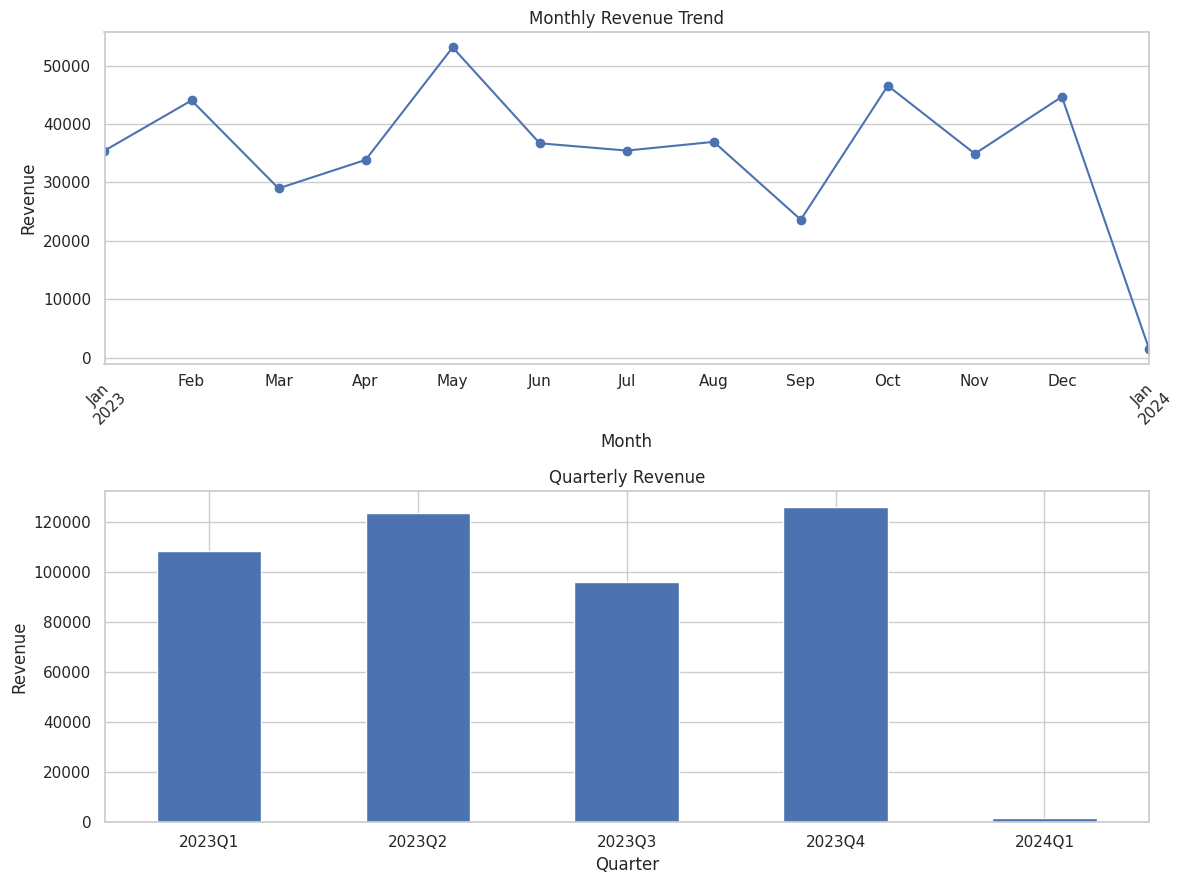

Highest-revenue month: 2023-05 with revenue 53150
Lowest-revenue month: 2024-01 with revenue 1530


In [7]:
if "Date" in df.columns and "Total Amount" in df.columns:
    dated = df.dropna(subset=["Date"]).copy()
    dated["Month"] = dated["Date"].dt.to_period("M").dt.to_timestamp()
    dated["Quarter"] = dated["Date"].dt.to_period("Q").astype(str)

    monthly_sales = dated.groupby("Month")["Total Amount"].sum().sort_index()
    quarterly_sales = dated.groupby("Quarter")["Total Amount"].sum()

    fig, axes = plt.subplots(2, 1, figsize=(12, 9))
    monthly_sales.plot(marker="o", ax=axes[0])
    axes[0].set_title("Monthly Revenue Trend")
    axes[0].set_xlabel("Month")
    axes[0].set_ylabel("Revenue")
    axes[0].tick_params(axis="x", rotation=45)

    quarterly_sales.plot(kind="bar", ax=axes[1])
    axes[1].set_title("Quarterly Revenue")
    axes[1].set_xlabel("Quarter")
    axes[1].set_ylabel("Revenue")
    axes[1].tick_params(axis="x", rotation=0)
    plt.tight_layout()
    plt.show()

    print("Highest-revenue month:", monthly_sales.idxmax().strftime("%Y-%m"),
          "with revenue", round(monthly_sales.max(), 2))
    print("Lowest-revenue month:", monthly_sales.idxmin().strftime("%Y-%m"),
          "with revenue", round(monthly_sales.min(), 2))
else:
    print("Date and/or Total Amount column is missing; update column names to run time-series analysis.")

**Observation prompt:** After viewing the charts, write 2–3 sentences here. Mention the strongest and weakest months/quarters and whether revenue appears stable, seasonal, or irregular. Base the observation on your actual chart, not assumptions.

## 7. Customer demographics: age groups and gender

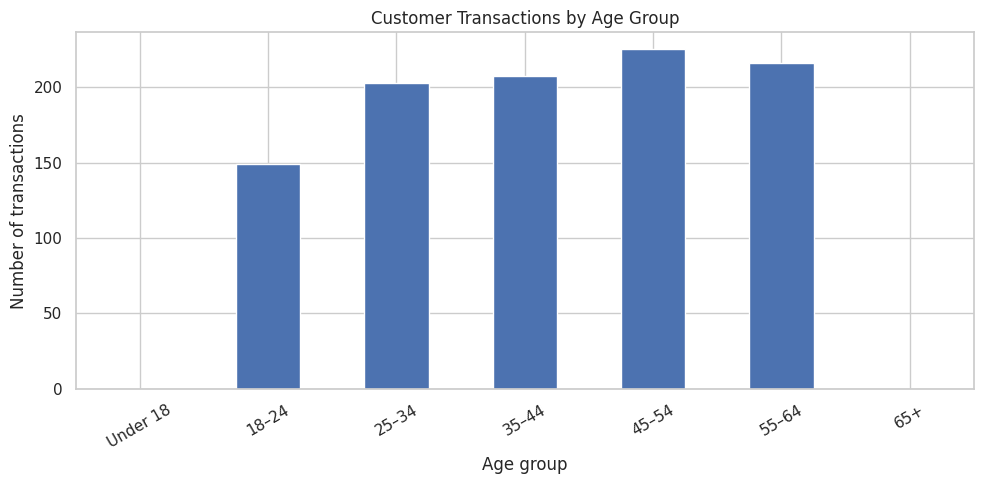

,Revenue by age group
Age Group,
45–54,97235
25–34,97090
35–44,96835
55–64,90190
18–24,74650
Under 18,0
65+,0


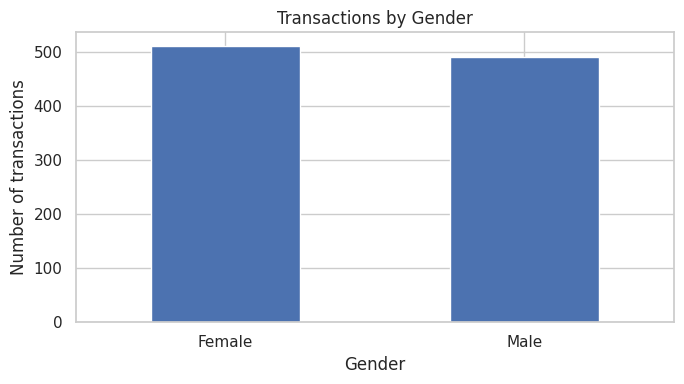

,Revenue by gender
Gender,
Female,232840
Male,223160


In [8]:
if "Age" in df.columns:
    bins = [0, 17, 24, 34, 44, 54, 64, np.inf]
    labels = ["Under 18", "18–24", "25–34", "35–44", "45–54", "55–64", "65+"]
    df["Age Group"] = pd.cut(df["Age"], bins=bins, labels=labels, include_lowest=True)

    age_counts = df["Age Group"].value_counts().sort_index()
    age_counts.plot(kind="bar", figsize=(10, 5), title="Customer Transactions by Age Group")
    plt.xlabel("Age group")
    plt.ylabel("Number of transactions")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

    if "Total Amount" in df.columns:
        age_revenue = df.groupby("Age Group", observed=False)["Total Amount"].sum()
        display(age_revenue.sort_values(ascending=False).to_frame("Revenue by age group"))

if "Gender" in df.columns:
    gender_counts = df["Gender"].value_counts()
    gender_counts.plot(kind="bar", figsize=(7, 4), title="Transactions by Gender")
    plt.xlabel("Gender")
    plt.ylabel("Number of transactions")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

    if "Total Amount" in df.columns:
        gender_revenue = df.groupby("Gender")["Total Amount"].sum().sort_values(ascending=False)
        display(gender_revenue.to_frame("Revenue by gender"))
else:
    print("Age and/or Gender column is missing; check your dataset columns.")

**Observation prompt:** Identify the largest age group by transaction count and by revenue. Compare revenue by gender without assuming that a larger total necessarily means a higher average spend.

## 8. Product/category performance

No individual product-name column found. This dataset supports category-level analysis, not a reliable top-10 individual product ranking.


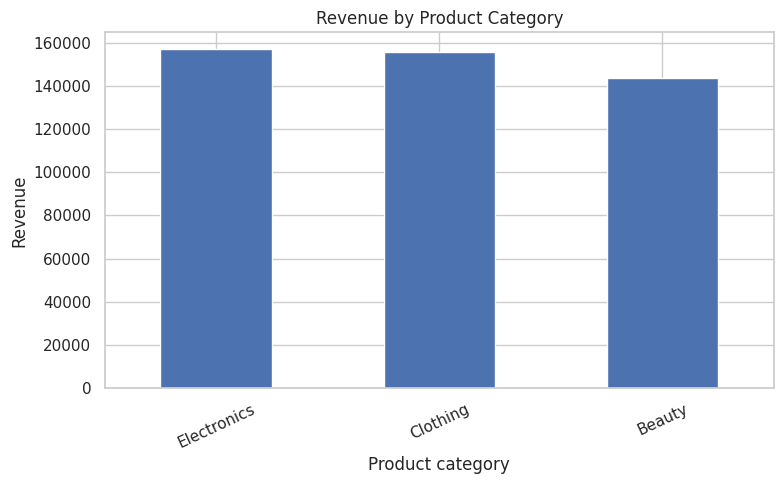

,Revenue
Product Category,
Electronics,156905
Clothing,155580
Beauty,143515


In [9]:
if "Total Amount" in df.columns:
    # If an individual product/name column exists, analyze it.
    product_col = next((c for c in ["Product", "Product Name", "Item", "Item Name"] if c in df.columns), None)

    if product_col:
        top_products = df.groupby(product_col)["Total Amount"].sum().sort_values(ascending=False).head(10)
        top_products.sort_values().plot(kind="barh", figsize=(10, 6), title="Top 10 Products by Revenue")
        plt.xlabel("Revenue")
        plt.ylabel("Product")
        plt.tight_layout()
        plt.show()
        display(top_products.to_frame("Revenue"))
    elif "Product Category" in df.columns:
        print("No individual product-name column found. This dataset supports category-level analysis, not a reliable top-10 individual product ranking.")
        category_revenue = df.groupby("Product Category")["Total Amount"].sum().sort_values(ascending=False)
        category_revenue.plot(kind="bar", figsize=(8, 5), title="Revenue by Product Category")
        plt.xlabel("Product category")
        plt.ylabel("Revenue")
        plt.xticks(rotation=25)
        plt.tight_layout()
        plt.show()
        display(category_revenue.to_frame("Revenue"))
    else:
        print("No product or category column was found. Check the dataset schema.")
else:
    print("Total Amount column is missing.")

**Observation prompt:** Name the best-performing product or category based on the chart. If the dataset only contains broad categories, state that limitation clearly rather than inventing product-level results.

## 9. Correlation heatmap

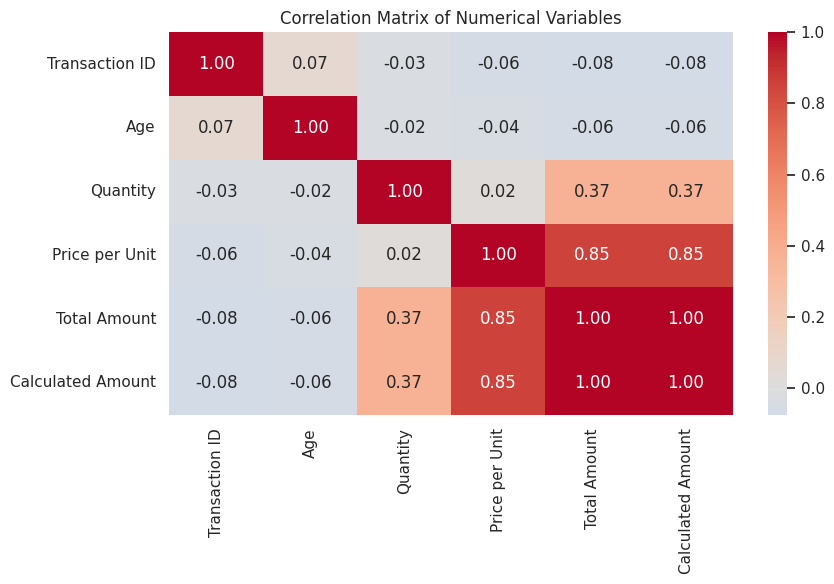

,Transaction ID,Age,Quantity,Price per Unit,Total Amount,Calculated Amount
Transaction ID,1.00,0.07,-0.03,-0.06,-0.08,-0.08
Age,0.07,1.00,-0.02,-0.04,-0.06,-0.06
Quantity,-0.03,-0.02,1.00,0.02,0.37,0.37
Price per Unit,-0.06,-0.04,0.02,1.00,0.85,0.85
Total Amount,-0.08,-0.06,0.37,0.85,1.00,1.00
Calculated Amount,-0.08,-0.06,0.37,0.85,1.00,1.00


In [10]:
corr_cols = df.select_dtypes(include=np.number).columns.tolist()
# Remove helper columns that duplicate information created for validation.
corr_cols = [c for c in corr_cols if c not in ["Amount Difference"]]

if len(corr_cols) >= 2:
    corr = df[corr_cols].corr(numeric_only=True)
    plt.figure(figsize=(9, 6))
    sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", center=0)
    plt.title("Correlation Matrix of Numerical Variables")
    plt.tight_layout()
    plt.show()
    display(corr)
else:
    print("At least two numeric columns are required for a correlation heatmap.")

**Observation prompt:** Describe the strongest relationships shown by the heatmap. Correlation indicates association, not proof that one variable causes another. If `Total Amount` is calculated from quantity and unit price, a strong correlation may be expected.

## 10. Additional visualization: order value distribution

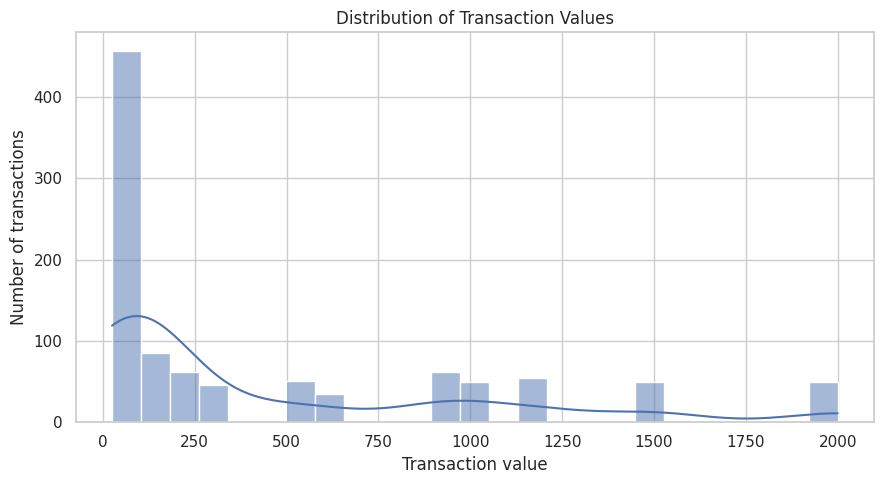

Average transaction value: 456.0
Median transaction value: 135.0


In [11]:
if "Total Amount" in df.columns:
    plt.figure(figsize=(9, 5))
    sns.histplot(df["Total Amount"].dropna(), bins=25, kde=True)
    plt.title("Distribution of Transaction Values")
    plt.xlabel("Transaction value")
    plt.ylabel("Number of transactions")
    plt.tight_layout()
    plt.show()

    print("Average transaction value:", round(df["Total Amount"].mean(), 2))
    print("Median transaction value:", round(df["Total Amount"].median(), 2))
else:
    print("Total Amount column is missing.")

**Observation prompt:** Compare the mean and median transaction values. If the mean is much higher than the median, a small number of high-value transactions may be pulling the average upward.

## 11. Key performance indicators

In [12]:
if "Total Amount" in df.columns:
    print(f"Total revenue: {df['Total Amount'].sum():,.2f}")
    print(f"Average transaction value: {df['Total Amount'].mean():,.2f}")
    print(f"Median transaction value: {df['Total Amount'].median():,.2f}")
    print(f"Number of records/transactions: {len(df):,}")

if "Customer ID" in df.columns:
    print(f"Unique customers: {df['Customer ID'].nunique():,}")

if "Quantity" in df.columns:
    print(f"Total units sold: {df['Quantity'].sum():,.0f}")

Total revenue: 456,000.00
Average transaction value: 456.00
Median transaction value: 135.00
Number of records/transactions: 1,000
Unique customers: 1,000
Total units sold: 2,514


## 12. Conclusion and actionable business recommendations

Complete this section after reviewing your actual outputs. Use your findings to fill in the brackets.

1. **Marketing by customer segment:** The age group with the highest revenue was **[insert group]**. Test a targeted campaign for this group and compare conversion rate and revenue against a control group.
2. **Product/category planning:** **[insert best-performing category/product]** generated the most revenue. Review its stock availability and evaluate complementary-product bundles; do not increase inventory without checking profit margin and stock turnover.
3. **Sales timing:** Revenue peaked in **[insert month/quarter]** and was lowest in **[insert month/quarter]**. Plan promotions and staffing around observed demand, then measure whether the plan improves sales.
4. **Transaction value:** The average transaction value was **[insert value]**, compared with a median of **[insert value]**. Test bundles or a minimum-spend offer if appropriate, and monitor profit as well as revenue.

### Limitations
- The findings describe this dataset and may not represent every retail business.
- Revenue is not the same as profit because costs and margins may be unavailable.
- If the file has only product categories and no product names, individual top-10 products cannot be identified from this dataset.
- Correlation does not establish causation.

## 13. Save a cleaned dataset (optional)

In [13]:
output_path = Path("../data/retail_sales_cleaned.csv")
try:
    output_path.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(output_path, index=False)
    print("Saved cleaned data to:", output_path)
except Exception as exc:
    print("Could not save to the repository data folder in this environment:", exc)

Saved cleaned data to: ../data/retail_sales_cleaned.csv
